# Validate linear summation (metamodel vs dynamic)

Compare offshore-driven **dynamic SnapWave** to the **reconstructed metamodel**.

- **`mm.reconstruct(..., spectral=True)`** — partitions ``0``–``3`` per goal, wavespectra linear sum (validation vs dynamic).
- **`mm.reconstruct(..., spectral=False)`** — bulk ``hs/tp/dir/spr`` per goal (partition ``-1``), same wavespectra sum.

**Prerequisites**

1. Models fitted — `06_Validate_Metamodel.ipynb` (`mm.fit_all`)
2. Dynamic run — `08_Dynamic_Cases_Generation.ipynb` → joined NetCDF

Validation loads saved models only (no refitting).

In [1]:
import matplotlib.pyplot as plt
import xarray as xr
from utils import metamodel as mm
from utils import validation as val
from utils.config import SIMULATIONS, resolve

## Configuration

In [2]:
period = "2020-05"
offshore_name = "WHACS"
mda_n = 450  # must match a fitted mda_candidates entry
pca_variance = {"hs": 0.95, "dir": 0.95}  # or 0.99, or {"hs": 0.99, "dir": 0.95}

# Site subset — isobath depth, mesh polygon, buoy id, or umbrella
sites = ["buoy_Aunuu_Buoy"]  # e.g. "10m", "buoy", ["10m", "buoy_Apolima_Buoy"]

dynamic_path = (
    resolve(SIMULATIONS["dynamic_cases"])
    / f"Dynamic_Cases_{offshore_name}_{period.replace('-', '')}.nc"
)

print(f"period       : {period}")
print(f"mda_n        : {mda_n}")
print(f"sites        : {sites}")
print(f"dynamic path : {dynamic_path}")

period       : 2020-05
mda_n        : 450
sites        : ['buoy_Aunuu_Buoy']
dynamic path : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/SnapWave_CASES_Dynamic/Dynamic_Cases_WHACS_202005.nc


## 1 · Check models

In [3]:
mm.require_models_all(mda_n, pca_variance=pca_variance)
print(f"common model sites: {len(mm.common_model_sites())}")

common model sites: 473


## 2 · Reconstruct metamodel (spectral)

In [10]:
metamodel = mm.reconstruct(
    period,
    mda_n,
    spectral=True,
    offshore_name=offshore_name,
    sites=sites,
    pca_variance=pca_variance,
)
metamodel

2026-06-30 09:47:48,493 - Samoa.metamodel - INFO - Reconstruction (partitions 0–3): time='2020-05', n=450, goals=['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11'], partitions=[0, 1, 2, 3], sites=1
INFO:ExactGPInterpolation:Preprocessing dataset for prediction
INFO:ExactGPInterpolation:Checking for NaNs in subset data
INFO:ExactGPInterpolation:Preprocessing subset data
INFO:ExactGPInterpolation:Normalizing subset data
INFO:ExactGPInterpolation:Subset data preprocessed successfully
INFO:ExactGPInterpolation:Predicting target variable: hs__PC1
INFO:ExactGPInterpolation:Predicting target variable: hs__PC2
INFO:ExactGPInterpolation:Predicting target variable: hs__PC3
INFO:ExactGPInterpolation:Predicting target variable: hs__PC4
INFO:ExactGPInterpolation:Predicting target variable: hs__PC5
INFO:ExactGPInterpolation:Predicting target variable: hs__PC6
INFO:ExactGPInterpolation:Predicting target variable: hs__PC7
INFO:ExactGPInterpolation:Predicting target variable: hs__PC8
INFO:ExactG

<xarray.Dataset> Size: 21kB
Dimensions:         (time: 744, sites: 1)
Coordinates:
  * time            (time) datetime64[ns] 6kB 2020-05-01 ... 2020-05-31T23:00:00
  * sites           (sites) <U24 96B 'buoy_Aunuu_Buoy'
    site_source     (sites) <U7 28B 'buoy'
    site_label      (sites) <U5 20B 'waves'
    site_depth      (sites) float64 8B -70.0
    site_longitude  (sites) float64 8B -170.5
    site_latitude   (sites) float64 8B -14.27
Data variables:
    hs              (time, sites) float64 6kB 1.119 1.047 1.061 ... 1.616 1.609
    tp              (time, sites) float32 3kB 8.938 8.89 8.875 ... 7.424 7.441
    dir             (time, sites) float64 6kB 30.63 38.13 37.36 ... 57.83 58.44
Attributes:
    comment:                Wind sea and swells defined using topographic par...
    globwave_name:          significant_wave_height_partition_0
    long_name:              Wave significant height partition 0
    units:                  m
    valid_max:              32000
    valid_min:              0
    coverage_content_type:  modelResult
    mesh:                   SMC
    standard_name:          sea_surface_wave_significant_height

## 3 · Load dynamic reference

In [11]:
dynamic = xr.open_dataset("SnapWave_CASES_Dynamic/Dynamic_Cases_WHACS_202005.nc").sel(
    time=period
)
site_ids = mm.resolve_reconstruction_sites(dynamic, sites)
dynamic = dynamic.sel(sites=site_ids).load()
dynamic

<xarray.Dataset> Size: 15kB
Dimensions:         (time: 744, sites: 1)
Coordinates:
  * time            (time) datetime64[ns] 6kB 2020-05-01 ... 2020-05-31T23:00:00
  * sites           (sites) <U24 96B 'buoy_Aunuu_Buoy'
    site_source     (sites) <U7 28B 'buoy'
    site_label      (sites) <U5 20B 'waves'
    site_depth      (sites) float64 8B -70.0
    site_longitude  (sites) float64 8B -170.5
    site_latitude   (sites) float64 8B -14.27
Data variables:
    hs              (time, sites) float32 3kB 1.031 1.056 1.081 ... 1.495 1.498
    tp              (time, sites) float32 3kB 9.592 9.591 9.641 ... 12.54 12.49
    dir             (time, sites) float32 3kB 74.55 74.58 74.55 ... 68.53 68.71
Attributes:
    Conventions:                         Conventions = 'CF-1.6, SGRID-0.3
    Build-Revision-Date-Netcdf-library:  4.9.2 of Mar 31 2024 08:09:36 $
    Producer:                            SnapWave
    title:                               Snapwave his point netcdf output

## 4 · Compare

In [13]:
result = val.compare(
    metamodel[["hs", "tp", "dir"]],
    dynamic[["hs", "tp", "dir"]],
    estimate_label="Linear summation",
    reference_label="Dynamic SnapWave",
)
result.metrics

2026-06-30 09:48:35,344 - Samoa.validation - INFO - Computed 3 validation metric row(s)


,group,site_source,site_label,variable,label,n,bias,rmse,r2,estimate_label,reference_label
0,buoy_Aunuu_Buoy,buoy,waves,hs,Hs,744,0.044048,0.117719,0.784294,Linear summation,Dynamic SnapWave
1,buoy_Aunuu_Buoy,buoy,waves,tp,Tp,744,-3.511556,4.335887,-4.698461,Linear summation,Dynamic SnapWave
2,buoy_Aunuu_Buoy,buoy,waves,dir,Dir,744,-36.104534,40.326055,-18.420975,Linear summation,Dynamic SnapWave


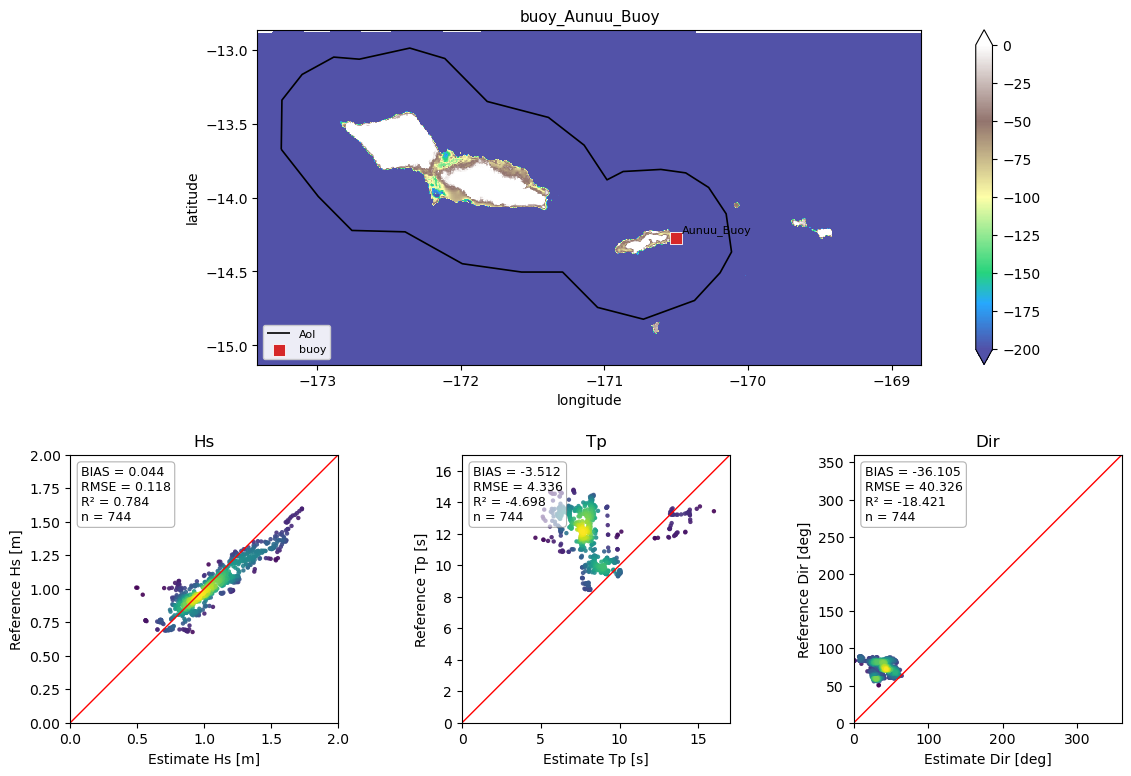

In [15]:
result.plot_all()
plt.show()